# 03 – Nettoyage Géométrique, Résolution des NaN Bâti et Reprojection

**Projet :** GeoIA Inondation Casablanca  
**Entrées (INPUT) :**
- Données OSM découpées (`donnees_decoupes/osm/`)
- Données de voirie Overpass (`donnees_brutes/routes/routes_casablanca.geojson`)
- Données hydrographiques découpées (`donnees_decoupes/hydrographie/`)
**Sortie (OUTPUT) :** Couches propres, dédoublonnées et reprojetées en **`EPSG:26191`** (`donnees_decoupes/casablanca_settat_clean/`)  

**Objectifs majeurs du prétraitement :**
1. **Résoudre les valeurs manquantes (NULL / NaN) sur le bâti** :
   - Imputation des noms manquants (`Non renseigné`).
   - Calcul de la surface au sol métrique exacte (`surface_m2`).
   - Classification en **3 typologies urbaines** basées sur la surface et la hauteur estimée :
     * **1. Bâti individuel (< 150 m², RDC/R+1, hauteur ~4.5m)** -> Vulnérabilité maximale.
     * **2. Bâti collectif (150 à 500 m², R+2 à R+5, hauteur ~12m)** -> Vulnérabilité moyenne.
     * **3. Grands complexes (>= 500 m², hangars/industriel, hauteur ~10m)** -> Vulnérabilité d'activité.
   - Remplacement des types manquants par la classe estimée.
2. **Intégrer les routes Overpass** : nettoyage, dédoublonnage et reprojection du réseau routier Casablanca.
3. **Nettoyer et réparer la topologie** : `make_valid` pour réparer les nœuds papillon, suppression des doublons stricts.
4. **Reprojeter en EPSG:26191** : passer en système métrique officiel (Merchich Nord Maroc) pour mesurer des distances et surfaces réelles.
5. **Exporter les couches finales** au format GeoPackage (`.gpkg`) avec le rapport d'audit CSV.

In [18]:

import os
import subprocess
import sys

env = os.environ.copy()

# Utiliser le certificat valide d'Anaconda
env["PIP_CERT"] = (
    r"C:\Users\espacegamers.ma\anaconda3"
    r"\Lib\site-packages\certifi\cacert.pem"
)

# Installer Folium dans le Python du notebook
result = subprocess.run(
    [sys.executable, "-m", "pip", "install", "folium"],
    env=env,
    capture_output=True,
    text=True
)

print("Code retour :", result.returncode)
print(result.stdout[-4000:])
print(result.stderr[-4000:])


Code retour : 0

   -------------------- ------------------- 1/2 [folium]
   ---------------------------------------- 2/2 [folium]





In [19]:
from pathlib import Path
import warnings
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import folium
from folium import LayerControl
import shapely
from shapely.validation import make_valid

warnings.filterwarnings('ignore', category=UserWarning)
print("✓ Bibliothèques chargées avec succès.")

✓ Bibliothèques chargées avec succès.


In [35]:
# =============================================================================
# CONFIGURATION DES CHEMINS (SOURCE RÉELLE : donnees_decoupes/casablanca_settat)
# =============================================================================
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "scripts":
    ROOT = ROOT.parent

# 1. Dossiers sources réels (avec casablanca_settat) :
DOSSIER_SOURCE_OSM = ROOT / "donnees_decoupes" / "casablanca_settat" / "osm"
DOSSIER_SOURCE_HYDRO = ROOT / "donnees_decoupes" / "casablanca_settat" / "hydrographie"
# 2. Dossier des routes dans donnees_brutes
DOSSIER_SOURCE_ROUTES = ROOT / "donnees_brutes" / "routes"

# 3. Dossier de destination pour les couches propres :
DOSSIER_SORTIE_CLEAN = ROOT / "donnees_traitees" / "casablanca_settat_clean"
DOSSIER_SORTIE_CLEAN.mkdir(parents=True, exist_ok=True)

CRS_CIBLE = "EPSG:26191"

print(f"✓ Source OSM : {DOSSIER_SOURCE_OSM} (Existe : {DOSSIER_SOURCE_OSM.exists()})")
print(f"✓ Source Hydro : {DOSSIER_SOURCE_HYDRO} (Existe : {DOSSIER_SOURCE_HYDRO.exists()})")


✓ Source OSM : C:\Users\espacegamers.ma\OneDrive\Desktop\geoai-inondation-casablanca\donnees_decoupes\casablanca_settat\osm (Existe : True)
✓ Source Hydro : C:\Users\espacegamers.ma\OneDrive\Desktop\geoai-inondation-casablanca\donnees_decoupes\casablanca_settat\hydrographie (Existe : True)


## 1. Audit Initial : Détection et Comptage des Valeurs NULL / NaN et Géométries Vides
Diagnostic préalable des colonnes attributaires et spatiales sur la couche Bâti avant traitement.

In [36]:
# =============================================================================
# AUDIT INITIAL : COMPTAGE DES VALEURS NULL / NaN ET GÉOMÉTRIES VIDES (BÂTI)
# =============================================================================

chemin_bati = DOSSIER_SOURCE_OSM / "gis_osm_buildings_a_free_1_casablanca_settat.gpkg"
gdf_bati_audit = gpd.read_file(chemin_bati)
total_entites = len(gdf_bati_audit)

print(f"📊 ANALYSE PRÉALABLE DU BÂTI SOURCE : {total_entites:,} entités au total\n")

lignes_audit = []
for col in gdf_bati_audit.columns:
    if col == "geometry":
        nb_null_geom = int(gdf_bati_audit.geometry.isna().sum())
        nb_vide_geom = int(gdf_bati_audit.geometry.is_empty.sum())
        nb_invalides = int((~gdf_bati_audit.geometry.is_valid).sum())
        
        lignes_audit.append({"Attribut": "geometry (NULL)", "Valeurs Manquantes / Défauts": nb_null_geom, "Taux (%)": f"{(nb_null_geom/total_entites)*100:.2f} %", "Action": "Éliminé par sécurité si > 0"})
        lignes_audit.append({"Attribut": "geometry (VIDE)", "Valeurs Manquantes / Défauts": nb_vide_geom, "Taux (%)": f"{(nb_vide_geom/total_entites)*100:.2f} %", "Action": "Éliminé par sécurité si > 0"})
        lignes_audit.append({"Attribut": "geometry (INVALIDE)", "Valeurs Manquantes / Défauts": nb_invalides, "Taux (%)": f"{(nb_invalides/total_entites)*100:.2f} %", "Action": "Réparé via make_valid()"})
    else:
        nb_nan = int(gdf_bati_audit[col].isna().sum())
        taux = (nb_nan / total_entites) * 100
        action = "Imputé ('Non renseigné' / 3 classes)" if nb_nan > 0 else "Complet (OK)"
        lignes_audit.append({"Attribut": col, "Valeurs Manquantes / Défauts": nb_nan, "Taux (%)": f"{taux:.2f} %", "Action": action})

df_audit_initial = pd.DataFrame(lignes_audit)
display(df_audit_initial.T)


📊 ANALYSE PRÉALABLE DU BÂTI SOURCE : 85,001 entités au total



,0,1,2,3,4,5,6,7
Attribut,osm_id,code,fclass,name,type,geometry (NULL),geometry (VIDE),geometry (INVALIDE)
Valeurs Manquantes / Défauts,0,0,0,82601,60668,0,0,0
Taux (%),0.00 %,0.00 %,0.00 %,97.18 %,71.37 %,0.00 %,0.00 %,0.00 %
Action,Complet (OK),Complet (OK),Complet (OK),Imputé ('Non renseigné' / 3 classes),Imputé ('Non renseigné' / 3 classes),Éliminé par sécurité si > 0,Éliminé par sécurité si > 0,Réparé via make_valid()


## 1. Classe d'Audit et de Nettoyage Géométrique
Méthodes pour diagnostiquer les anomalies avant traitement, réparer, dédoublonner et reprojeter.

In [27]:
class AuditeurGeometrique:
    """
    Classe pour auditer, nettoyer, enrichir et reprojeter les couches spatiales.
    """
    
    @staticmethod
    def diagnostiquer(gdf, nom_couche):
        """Évalue l'état de la couche (effectif, vides, doublons, géométries invalides)."""
        nb_total = len(gdf)
        if nb_total == 0:
            return {"couche": nom_couche, "total": 0, "invalides": 0, "vides": 0, "doublons_geom": 0, "crs": str(gdf.crs)}
            
        nb_vides = int((gdf.geometry.isna() | gdf.geometry.is_empty).sum())
        gdf_valides = gdf[gdf.geometry.notna() & ~gdf.geometry.is_empty]
        nb_invalides = int((~gdf_valides.geometry.is_valid).sum())
        
        # Doublons géométriques (WKT identique)
        geom_wkt = gdf_valides.geometry.to_wkt()
        nb_doublons = int(geom_wkt.duplicated().sum())
        
        return {
            "couche": nom_couche,
            "total": nb_total,
            "invalides": nb_invalides,
            "vides": nb_vides,
            "doublons_geom": nb_doublons,
            "crs": str(gdf.crs)
        }
    
    @staticmethod
    def resoudre_nan_et_typer_bati(gdf, crs_cible="EPSG:26191"):
        """
        Résout les valeurs NULL / NaN sur la couche du bâti :
        1. Remplace les noms vides par 'Non renseigné'.
        2. Calcule la surface au sol exacte en m² (EPSG:26191).
        3. Classifie en 3 typologies urbaines basées sur la surface et la hauteur estimée :
           - 1_Individuel_<150m2 : Maisons individuelles, RDC/R+1 (~4.5m) -> Vulnérabilité maximale
           - 2_Collectif_150_500m2 : Immeubles d'habitation R+2 à R+5 (~12m) -> Vulnérabilité moyenne
           - 3_GrandComplexe_>=500m2 : Hangars, entrepôts, commerces (~10m) -> Vulnérabilité spécifique
        4. Remplace les types manquants par la classe estimée (tout en conservant les POI explicites).
        """
        print("  -> Traitement des attributs manquants (NULL / NaN) sur le Bâti...")
        gdf_out = gdf.copy()
        
        # 1. Imputation des noms
        if "name" in gdf_out.columns:
            gdf_out["name"] = gdf_out["name"].fillna("Non renseigné")
            
        # 2. Calcul métrique de la surface au sol
        if gdf_out.crs != crs_cible:
            gdf_proj = gdf_out.to_crs(crs_cible)
            gdf_out["surface_m2"] = gdf_proj.geometry.area.round(2)
        else:
            gdf_out["surface_m2"] = gdf_out.geometry.area.round(2)
            
        # 3. Définition des 3 classes basées sur la surface
        gdf_out["classe_bati_3cas"] = gdf_out["surface_m2"].apply(
            lambda s: "1_Individuel_<150m2" if s < 150 else (
                "2_Collectif_150_500m2" if s < 500 else "3_GrandComplexe_>=500m2"
            )
        )
        
        # Estimation de la hauteur selon la morphologie du bâti
        gdf_out["hauteur_estimee_m"] = gdf_out["surface_m2"].apply(
            lambda s: 4.5 if s < 150 else (12.0 if s < 500 else 10.0)
        )
        
        # 4. Imputation de la colonne 'type' si manquante
        if "type" in gdf_out.columns:
            gdf_out["type"] = gdf_out["type"].fillna(gdf_out["classe_bati_3cas"])
        else:
            gdf_out["type"] = gdf_out["classe_bati_3cas"]
            
        print("     ✓ Noms et types NULL résolus avec succès (0 valeur NaN restante).")
        print("     ✓ Répartition des 3 classes de bâti :")
        for nom_cls, eff in gdf_out["classe_bati_3cas"].value_counts().items():
            print(f"       * {nom_cls} : {eff:,} entités")
        return gdf_out
    
    @staticmethod
    def nettoyer_et_reprojeter(gdf, nom_couche, type_geom_attendu=None, crs_cible="EPSG:26191"):
        """
        Nettoie et reprojette une couche spatiale :
        1. Purge des géométries nulles ou vides
        2. make_valid (réparation des auto-intersections)
        3. Filtrage du type géométrique pour éviter les GeometryCollection
        4. Dédoublonnage géométrique strict
        5. Dédoublonnage attributaire sur osm_id si présent
        6. Reprojection vers EPSG:26191 (mètres)
        """
        print(f"\n[NETTOYAGE] {nom_couche} (Entrées initiales : {len(gdf)})...")
        
        # 1. Purge des géométries vides/nulles
        gdf_clean = gdf[gdf.geometry.notna() & ~gdf.geometry.is_empty].copy()
        
        # 2. Réparation topologique
        gdf_clean["geometry"] = gdf_clean.geometry.apply(make_valid)
        
        # 3. Filtrage des types géométriques
        if type_geom_attendu:
            gdf_clean = gdf_clean[gdf_clean.geometry.geom_type.isin(type_geom_attendu)].copy()
            
        # 4. Suppression des doublons géométriques stricts
        wkt_series = gdf_clean.geometry.to_wkt()
        gdf_clean = gdf_clean.loc[~wkt_series.duplicated()].copy()
        
        # 5. Suppression des doublons d'identifiant OSM si présents
        if "osm_id" in gdf_clean.columns:
            gdf_clean = gdf_clean.drop_duplicates(subset=["osm_id"]).copy()
            
        # 6. Reprojection vers EPSG:26191
        if gdf_clean.crs != crs_cible:
            gdf_clean = gdf_clean.to_crs(crs_cible)
            
        # Validation finale
        gdf_clean["geometry"] = gdf_clean.geometry.apply(make_valid)
        gdf_clean = gdf_clean[gdf_clean.geometry.notna() & ~gdf_clean.geometry.is_empty].copy()
        
        print(f"  -> Nettoyé avec succès : {len(gdf_clean)} entités valides en {crs_cible}.")
        return gdf_clean

print("✓ Classe AuditeurGeometrique configurée.")


✓ Classe AuditeurGeometrique configurée.


## 2. Fonctions d'Illustration (Matplotlib & Folium)

In [37]:
def tracer_comparaison_statistique(nom_couche, diag_av, diag_ap):
    """Affiche un graphique en barres comparant l'état avant et après nettoyage."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
    fig.suptitle(f"Audit Qualité : {nom_couche}", fontsize=12, fontweight='bold')
    
    # Graphique 1 : Effectif avant vs après
    etats = ["Découpé (WGS84)", "Clean (EPSG:26191)"]
    totaux = [diag_av["total"], diag_ap["total"]]
    bars1 = ax1.bar(etats, totaux, color=["#6c8ebf", "#82b366"], edgecolor='black', width=0.45)
    ax1.set_ylabel("Nombre d'entités")
    ax1.set_title("Évolution du nombre d'entités")
    ax1.grid(axis='y', linestyle='--', alpha=0.5)
    for bar in bars1:
        yval = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2.0, yval, f"{int(yval):,}", ha='center', va='bottom', fontweight='bold')
        
    # Graphique 2 : Élimination des anomalies (invalides, vides, doublons)
    categories = ["Invalides", "Vides", "Doublons"]
    valeurs_avant = [diag_av["invalides"], diag_av["vides"], diag_av["doublons_geom"]]
    valeurs_apres = [diag_ap["invalides"], diag_ap["vides"], diag_ap["doublons_geom"]]
    
    x = np.arange(len(categories))
    w = 0.35
    rects1 = ax2.bar(x - w/2, valeurs_avant, w, label='Avant (Anomalies)', color='#f8cecc', edgecolor='black')
    rects2 = ax2.bar(x + w/2, valeurs_apres, w, label='Après (Clean)', color='#d5e8d4', edgecolor='black')
    ax2.set_ylabel("Anomalies")
    ax2.set_title("Suppression des défauts et doublons")
    ax2.set_xticks(x)
    ax2.set_xticklabels(categories)
    ax2.legend()
    ax2.grid(axis='y', linestyle='--', alpha=0.5)
    for bar in rects1:
        yval = bar.get_height()
        if yval > 0:
            ax2.text(bar.get_x() + bar.get_width()/2.0, yval, f"{int(yval)}", ha='center', va='bottom')
            
    plt.tight_layout()
    plt.show()


def creer_carte_interactive_folium(gdf_clean, nom_couche, max_entites=400):
    """Affiche un échantillon fluide de la couche propre sur fond OpenStreetMap."""
    gdf_4326 = gdf_clean.to_crs("EPSG:4326")
    if len(gdf_4326) > max_entites:
        gdf_sample = gdf_4326.sample(n=max_entites, random_state=42)
        titre = f"{nom_couche} (Échantillon {max_entites} entités)"
    else:
        gdf_sample = gdf_4326
        titre = f"{nom_couche} ({len(gdf_sample)} entités)"
        
    bounds = gdf_sample.total_bounds
    centre = [(bounds[1] + bounds[3]) / 2, (bounds[0] + bounds[2]) / 2]
    m = folium.Map(location=centre, zoom_start=11, tiles="CartoDB positron")
    
    gtype = gdf_sample.geom_type.iloc[0]
    if "Polygon" in gtype:
        folium.GeoJson(gdf_sample, name=titre, style_function=lambda x: {'fillColor': '#3186cc', 'color': '#003366', 'weight': 1, 'fillOpacity': 0.4}).add_to(m)
    elif "Line" in gtype:
        folium.GeoJson(gdf_sample, name=titre, style_function=lambda x: {'color': '#e74c3c', 'weight': 2.5, 'opacity': 0.8}).add_to(m)
    else:
        for _, r in gdf_sample.iterrows():
            folium.CircleMarker(location=[r.geometry.y, r.geometry.x], radius=4, color="#27ae60", fill=True, fill_opacity=0.8).add_to(m)
            
    folium.LayerControl().add_to(m)
    return m

print("✓ Outils de visualisation prêts.")

✓ Outils de visualisation prêts.


## 3. Prétraitement du Bâti, de la Voirie Overpass et des Couches OSM
- **Bâti** : résolution préalable des NaN (`name`, `type`), calcul de `surface_m2`, `hauteur_estimee_m` et classification en 3 cas.
- **Routes** : chargement direct depuis les données Overpass (`donnees_brutes/routes/routes_casablanca.geojson`).
- **Occupation du sol, POI, Secours** : nettoyage et reprojection métrique.

  -> Traitement des attributs manquants (NULL / NaN) sur le Bâti...
     ✓ Noms et types NULL résolus avec succès (0 valeur NaN restante).
     ✓ Répartition des 3 classes de bâti :
       * 2_Collectif_150_500m2 : 35,519 entités
       * 1_Individuel_<150m2 : 34,569 entités
       * 3_GrandComplexe_>=500m2 : 14,913 entités

[NETTOYAGE] Bati (Entrées initiales : 85001)...
  -> Nettoyé avec succès : 85001 entités valides en EPSG:26191.
  -> Fichier final : bati_casablanca_settat_clean.gpkg


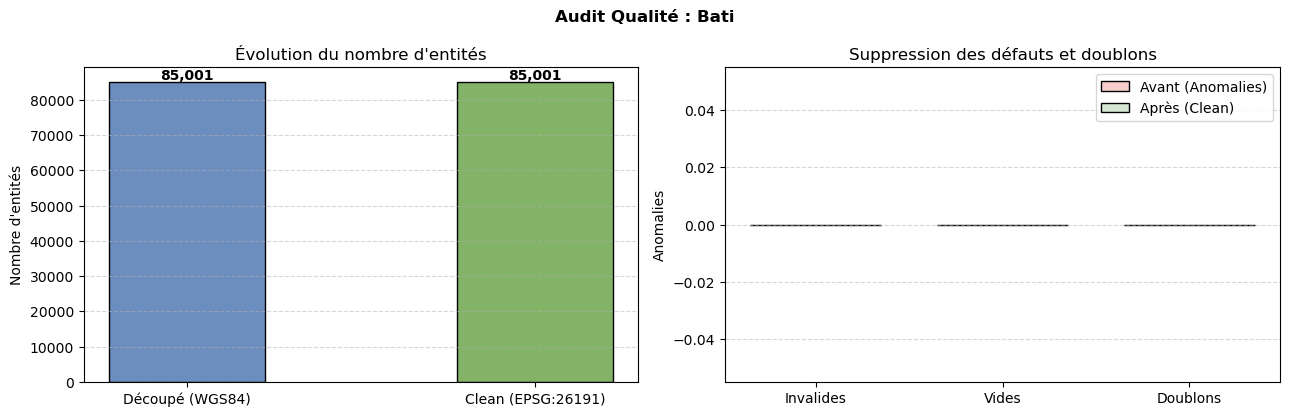

⚠️ Fichier source absent : C:\Users\espacegamers.ma\OneDrive\Desktop\geoai-inondation-casablanca\donnees_decoupes\Overpass\routes_casablanca.geojson

[NETTOYAGE] OccupationSol (Entrées initiales : 11811)...
  -> Nettoyé avec succès : 11805 entités valides en EPSG:26191.
  -> Fichier final : occupation_sol_casablanca_settat_clean.gpkg


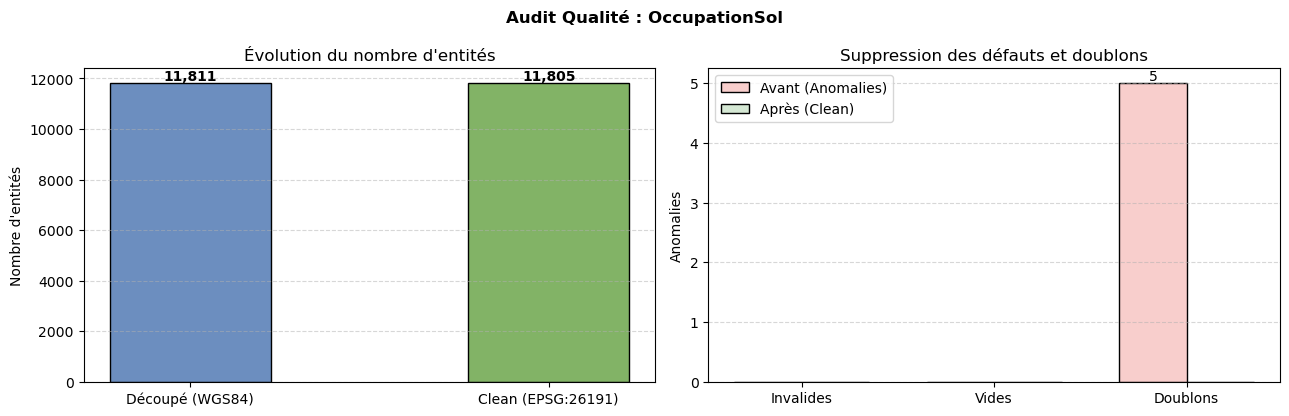


[NETTOYAGE] Equipements_POI (Entrées initiales : 7347)...
  -> Nettoyé avec succès : 7341 entités valides en EPSG:26191.
  -> Fichier final : equipements_poi_casablanca_settat_clean.gpkg


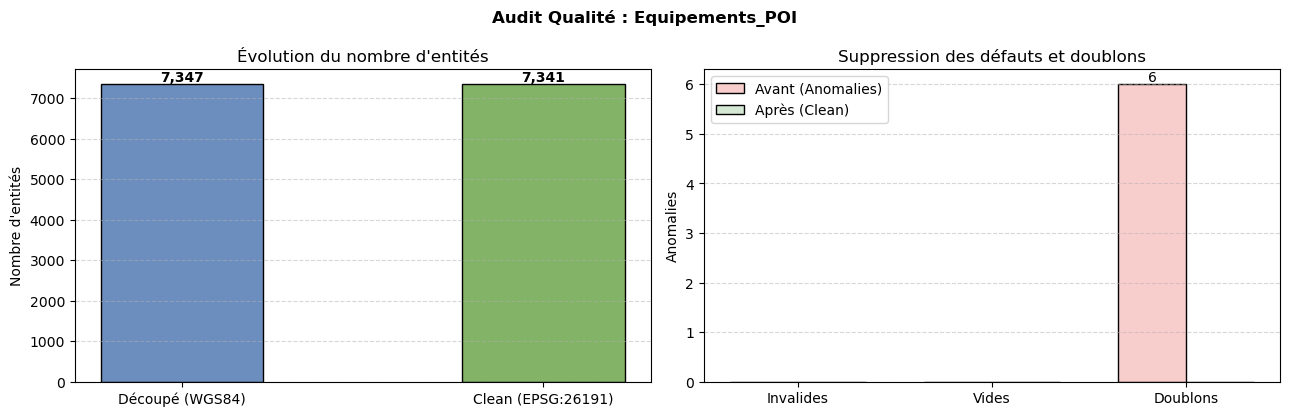


[NETTOYAGE] Infrastructures_Secours (Entrées initiales : 9264)...
  -> Nettoyé avec succès : 9263 entités valides en EPSG:26191.
  -> Fichier final : infrastructures_secours_clean.gpkg


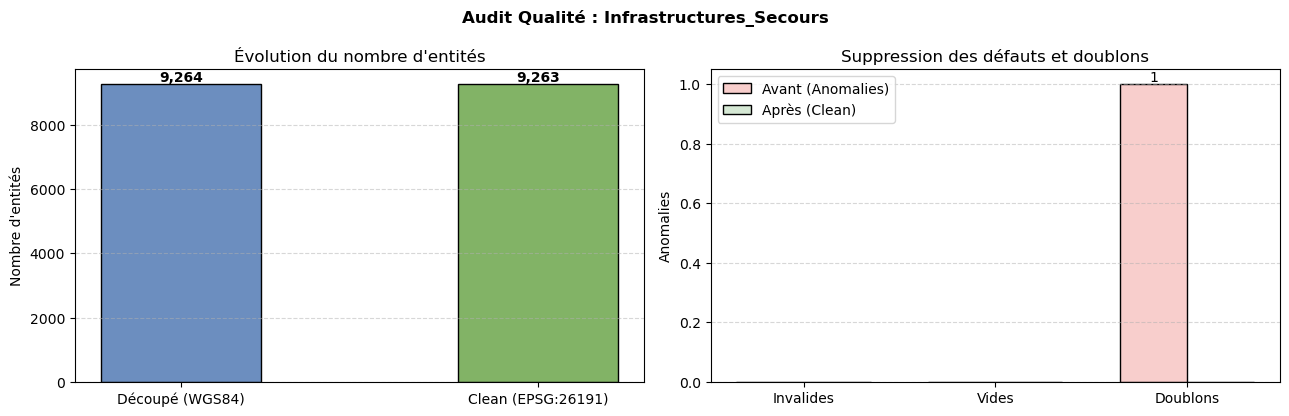

In [38]:
COUCHES_OSM_DECOUPES = [
    {
        "nom": "Bati",
        "dossier": DOSSIER_SOURCE_OSM,
        "fichier_in": "gis_osm_buildings_a_free_1_casablanca_settat.gpkg",
        "types": ["Polygon", "MultiPolygon"],
        "sortie": "bati_casablanca_settat_clean.gpkg",
        "is_bati": True
    },
    {
        "nom": "Route_Overpass",
        "dossier": DOSSIER_SOURCE_ROUTES,
        "fichier_in": "routes_casablanca.geojson",
        "types": ["LineString", "MultiLineString"],
        "sortie": "routes_casablanca_settat_clean.gpkg",
        "is_bati": False
    },
    {
        "nom": "OccupationSol",
        "dossier": DOSSIER_SOURCE_OSM,
        "fichier_in": "gis_osm_landuse_a_free_1_casablanca_settat.gpkg",
        "types": ["Polygon", "MultiPolygon"],
        "sortie": "occupation_sol_casablanca_settat_clean.gpkg",
        "is_bati": False
    },
    {
        "nom": "Equipements_POI",
        "dossier": DOSSIER_SOURCE_OSM,
        "fichier_in": "gis_osm_pois_free_1_casablanca_settat.gpkg",
        "types": ["Point", "MultiPoint"],
        "sortie": "equipements_poi_casablanca_settat_clean.gpkg",
        "is_bati": False
    },
    {
        "nom": "Infrastructures_Secours",
        "dossier": DOSSIER_SOURCE_OSM,
        "fichier_in": "gis_osm_traffic_free_1_casablanca_settat.gpkg",
        "types": ["Point", "MultiPoint"],
        "sortie": "infrastructures_secours_clean.gpkg",
        "is_bati": False
    }
]

rapport_clean = []

for cfg in COUCHES_OSM_DECOUPES:
    dossier_source = cfg.get("dossier", DOSSIER_SOURCE_OSM)
    chemin_in = dossier_source / cfg["fichier_in"]
    if not chemin_in.exists():
        print(f"⚠️ Fichier source absent : {chemin_in}")
        continue
        
    # 1. Lecture de la couche source
    gdf_in = gpd.read_file(chemin_in)
    audit_av = AuditeurGeometrique.diagnostiquer(gdf_in, cfg["nom"])
    
    # Résolution préalable des NaN et typologie pour le bâti
    if cfg.get("is_bati", False):
        gdf_in = AuditeurGeometrique.resoudre_nan_et_typer_bati(gdf_in, crs_cible=CRS_CIBLE)
        
    # 2. Nettoyage, dédoublonnage et reprojection en EPSG:26191
    gdf_clean = AuditeurGeometrique.nettoyer_et_reprojeter(
        gdf=gdf_in,
        nom_couche=cfg["nom"],
        type_geom_attendu=cfg["types"],
        crs_cible=CRS_CIBLE
    )
    audit_ap = AuditeurGeometrique.diagnostiquer(gdf_clean, cfg["nom"])
    
    # 3. Exportation GeoPackage
    chemin_out = DOSSIER_SORTIE_CLEAN / cfg["sortie"]
    gdf_clean.to_file(chemin_out, driver="GPKG")
    print(f"  -> Fichier final : {chemin_out.name}")
    
    rapport_clean.append({
        "Couche": cfg["nom"],
        "Source": str(dossier_source.name) + "/" + cfg["fichier_in"],
        "Entites_Initiales": audit_av["total"],
        "Invalides_Reparees": audit_av["invalides"],
        "Vides_Supprimees": audit_av["vides"],
        "Doublons_Supprimes": audit_av["doublons_geom"],
        "Entites_Clean_Final": audit_ap["total"],
        "CRS_Initial": audit_av["crs"],
        "CRS_Final": audit_ap["crs"]
    })
    
    # 4. Illustration graphique Matplotlib
    tracer_comparaison_statistique(cfg["nom"], audit_av, audit_ap)


## 4. Nettoyage des Couches Découpées Hydrographiques (CartoMaroc)
Lecture depuis `donnees_decoupes/hydrographie/` ➔ Nettoyage ➔ Export vers `donnees_decoupes/casablanca_settat_clean/`.


[NETTOYAGE] Oued_Detaille (Entrées initiales : 4000)...
  -> Nettoyé avec succès : 1334 entités valides en EPSG:26191.
  -> Fichier final : oued_detaille_casablanca_settat_clean.gpkg


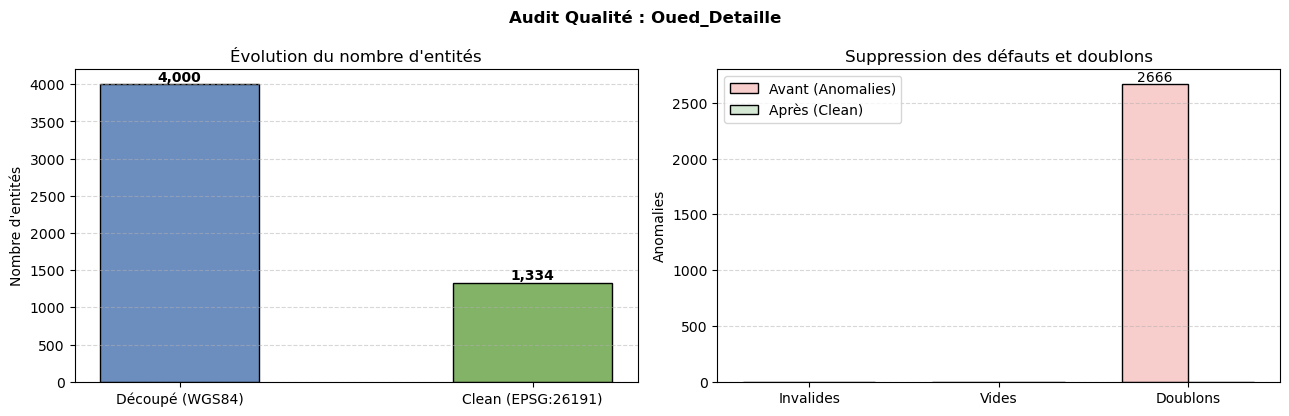


[NETTOYAGE] Oued_Principal (Entrées initiales : 276)...
  -> Nettoyé avec succès : 268 entités valides en EPSG:26191.
  -> Fichier final : oued_principal_casablanca_settat_clean.gpkg


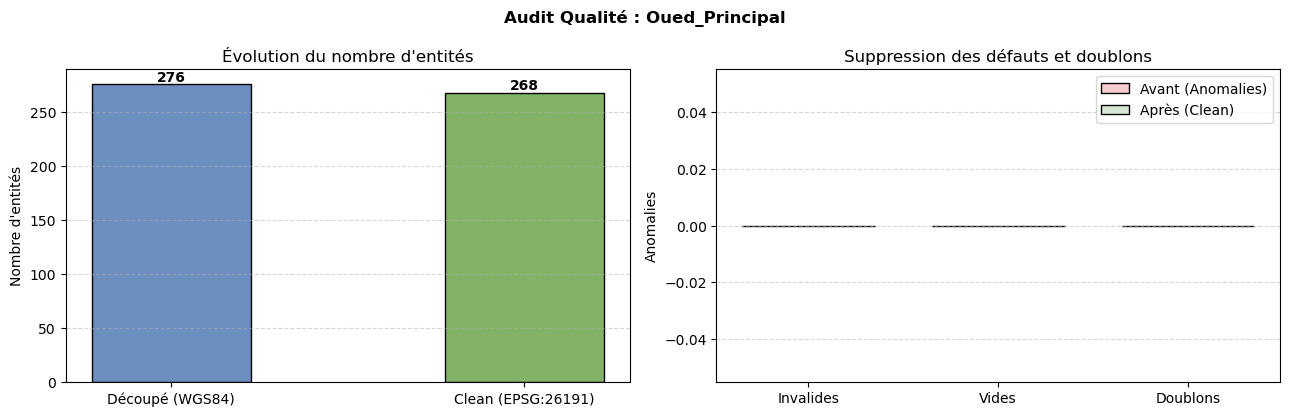

In [39]:
COUCHES_HYDRO_DECOUPES = [
    {
        "nom": "Oued_Detaille",
        "fichier_in": "Oued-Détaillé(CartoMaroc)_casablanca_settat.gpkg",
        "types": ["LineString", "MultiLineString"],
        "sortie": "oued_detaille_casablanca_settat_clean.gpkg"
    },
    {
        "nom": "Oued_Principal",
        "fichier_in": "Oued(CartoMaroc) (1)_casablanca_settat.gpkg",
        "types": ["LineString", "MultiLineString"],
        "sortie": "oued_principal_casablanca_settat_clean.gpkg"
    },
    
]

for cfg in COUCHES_HYDRO_DECOUPES:
    chemin_in = DOSSIER_SOURCE_HYDRO / cfg["fichier_in"]
    if not chemin_in.exists():
        print(f"⚠️ Fichier hydrographique découpé absent : {cfg['fichier_in']}")
        continue
        
    gdf_decoupe = gpd.read_file(chemin_in)
    audit_av = AuditeurGeometrique.diagnostiquer(gdf_decoupe, cfg["nom"])
    
    gdf_clean = AuditeurGeometrique.nettoyer_et_reprojeter(
        gdf=gdf_decoupe,
        nom_couche=cfg["nom"],
        type_geom_attendu=cfg["types"],
        crs_cible=CRS_CIBLE
    )
    audit_ap = AuditeurGeometrique.diagnostiquer(gdf_clean, cfg["nom"])
    
    chemin_out = DOSSIER_SORTIE_CLEAN / cfg["sortie"]
    gdf_clean.to_file(chemin_out, driver="GPKG")
    print(f"  -> Fichier final : {chemin_out.name}")
    
    rapport_clean.append({
        "Couche": cfg["nom"],
        "Source": "hydrographie/" + cfg["fichier_in"],
        "Entites_Initiales": audit_av["total"],
        "Invalides_Reparees": audit_av["invalides"],
        "Vides_Supprimees": audit_av["vides"],
        "Doublons_Supprimes": audit_av["doublons_geom"],
        "Entites_Clean_Final": audit_ap["total"],
        "CRS_Initial": audit_av["crs"],
        "CRS_Final": audit_ap["crs"]
    })
    
    tracer_comparaison_statistique(cfg["nom"], audit_av, audit_ap)


## 5. Synthèse Globale & Export du Rapport CSV Final

✓ Total bâtiments analysés : 85,001

1. LES 3 CLASSES DE VULNÉRABILITÉ (HOMOGÈNES POUR 100% DU BÂTI)


,Effectif,Proportion (%),Surface Totale (m²)
classe_bati_3cas,,,
1_Individuel_<150m2,34569,40.67,3537845.0
2_Collectif_150_500m2,35519,41.79,9339801.0
3_GrandComplexe_>=500m2,14913,17.54,27477046.0



2. DÉTAIL DE TOUS LES TYPES PRÉSENTS DANS LA COLONNE 'type'


,Nombre de bâtiments,Proportion (%)
type,,
1_Individuel_<150m2,30085,35.39
2_Collectif_150_500m2,20426,24.03
house,11152,13.12
3_GrandComplexe_>=500m2,10157,11.95
apartments,9355,11.01
...,...,...
conservatory,1,0.00
police,1,0.00
cinema,1,0.00



3. CROISEMENT : OÙ SE SITUENT LES TYPES D'ORIGINE DANS LES 3 CLASSES ?


classe_bati_3cas,1_Individuel_<150m2,2_Collectif_150_500m2,3_GrandComplexe_>=500m2
type,,,
1_Individuel_<150m2,30085,0,0
2_Collectif_150_500m2,0,20426,0
house,2519,8241,392
3_GrandComplexe_>=500m2,0,0,10157
apartments,1000,5235,3120
residential,416,320,188
terrace,58,374,191
school,41,154,174
commercial,80,187,95


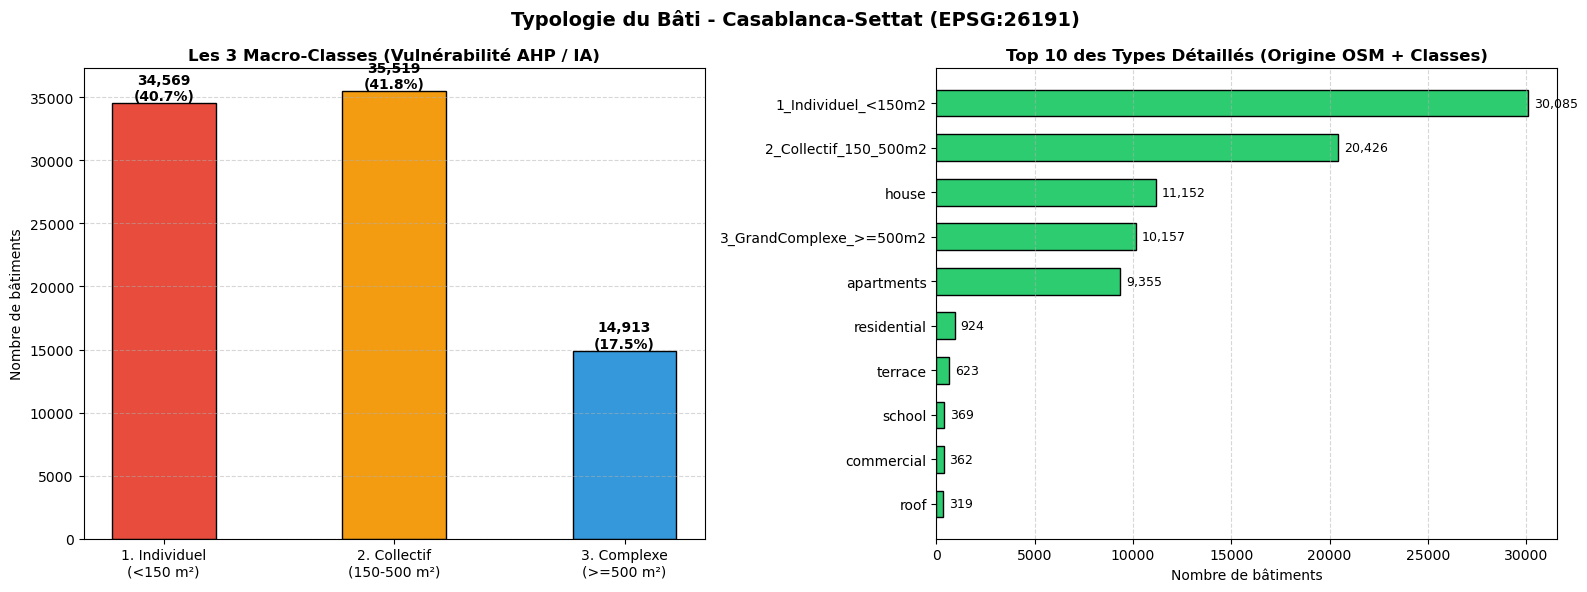

In [40]:
# =============================================================================
# VISUALISATION COMPLÈTE : LES 3 CLASSES + DÉTAIL DES TYPES D'ORIGINE OSM
# =============================================================================

import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

# 1. Chargement de la couche clean
chemin_bati_clean = DOSSIER_SORTIE_CLEAN / "bati_casablanca_settat_clean.gpkg"
gdf_clean_bati = gpd.read_file(chemin_bati_clean)

print(f"✓ Total bâtiments analysés : {len(gdf_clean_bati):,}\n")

# =============================================================================
# TABLEAU 1 : RÉPARTITION DES 3 MACRO-CLASSES (SURFACE + HAUTEUR)
# =============================================================================
print("=============================================================================")
print("1. LES 3 CLASSES DE VULNÉRABILITÉ (HOMOGÈNES POUR 100% DU BÂTI)")
print("=============================================================================")
tab_3classes = pd.DataFrame({
    'Effectif': gdf_clean_bati['classe_bati_3cas'].value_counts(),
    'Proportion (%)': (gdf_clean_bati['classe_bati_3cas'].value_counts(normalize=True) * 100).round(2),
    'Surface Totale (m²)': gdf_clean_bati.groupby('classe_bati_3cas')['surface_m2'].sum().round(0)
})
display(tab_3classes)

# =============================================================================
# TABLEAU 2 : DÉTAIL DE TOUS LES TYPES (ORIGINAUX OSM + IMPUTATIONS)
# =============================================================================
print("\n=============================================================================")
print("2. DÉTAIL DE TOUS LES TYPES PRÉSENTS DANS LA COLONNE 'type'")
print("=============================================================================")
tab_tous_types = pd.DataFrame({
    'Nombre de bâtiments': gdf_clean_bati['type'].value_counts(),
    'Proportion (%)': (gdf_clean_bati['type'].value_counts(normalize=True) * 100).round(2)
})
display(tab_tous_types)

# =============================================================================
# TABLEAU 3 : CROISEMENT (TYPES ORIGINAUX vs LES 3 CLASSES)
# =============================================================================
print("\n=============================================================================")
print("3. CROISEMENT : OÙ SE SITUENT LES TYPES D'ORIGINE DANS LES 3 CLASSES ?")
print("=============================================================================")
croisement = pd.crosstab(gdf_clean_bati['type'], gdf_clean_bati['classe_bati_3cas'])
# Affichage des 12 types les plus fréquents
display(croisement.loc[gdf_clean_bati['type'].value_counts().head(12).index])

# =============================================================================
# 4. VISUALISATION GRAPHIQUE (2 PANNEAUX COMPARATIFS)
# =============================================================================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("Typologie du Bâti - Casablanca-Settat (EPSG:26191)", fontsize=14, fontweight='bold')

# Panneau Gauche : Les 3 Classes Globales
bars1 = ax1.bar(
    ["1. Individuel\n(<150 m²)", "2. Collectif\n(150-500 m²)", "3. Complexe\n(>=500 m²)"],
    tab_3classes['Effectif'],
    color=['#e74c3c', '#f39c12', '#3498db'],
    edgecolor='black',
    width=0.45
)
ax1.set_title("Les 3 Macro-Classes (Vulnérabilité AHP / IA)", fontweight='bold')
ax1.set_ylabel("Nombre de bâtiments")
ax1.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars1:
    y = bar.get_height()
    pct = (y / len(gdf_clean_bati)) * 100
    ax1.text(bar.get_x() + bar.get_width()/2.0, y, f"{int(y):,}\n({pct:.1f}%)", ha='center', va='bottom', fontweight='bold')

# Panneau Droit : Top 10 des types détaillés (incluant house, apartments, school, commercial...)
top_types = gdf_clean_bati['type'].value_counts().head(10)
bars2 = ax2.barh(top_types.index[::-1], top_types.values[::-1], color='#2ecc71', edgecolor='black', height=0.6)
ax2.set_title("Top 10 des Types Détaillés (Origine OSM + Classes)", fontweight='bold')
ax2.set_xlabel("Nombre de bâtiments")
ax2.grid(axis='x', linestyle='--', alpha=0.5)

for bar in bars2:
    w = bar.get_width()
    ax2.text(w + 300, bar.get_y() + bar.get_height()/2.0, f"{int(w):,}", ha='left', va='center', fontsize=9)

plt.tight_layout()
plt.show()

In [41]:
df_clean_rapport = pd.DataFrame(rapport_clean)
print("\n=============================================================================")
print("BILAN GLOBAL DU NETTOYAGE ET DE LA REPROJECTION (EPSG:26191)")
print("=============================================================================")
display(df_clean_rapport)

CHEMIN_RAPPORT_CSV = ROOT / "donnees_decoupes" / "rapport_nettoyage_geometries.csv"
CHEMIN_RAPPORT_CSV.parent.mkdir(parents=True, exist_ok=True)

try:
    df_clean_rapport.to_csv(CHEMIN_RAPPORT_CSV, index=False, encoding="utf-8-sig")
    print(f"✓ Rapport enregistré avec succès dans : {CHEMIN_RAPPORT_CSV}")
except PermissionError:
    CHEMIN_RAPPORT_CSV = CHEMIN_RAPPORT_CSV.with_name("rapport_nettoyage_geometries_v2.csv")
    df_clean_rapport.to_csv(CHEMIN_RAPPORT_CSV, index=False, encoding="utf-8-sig")
    print(f"✓ Fichier d'origine verrouillé, sauvegarde effectuée dans : {CHEMIN_RAPPORT_CSV}")



BILAN GLOBAL DU NETTOYAGE ET DE LA REPROJECTION (EPSG:26191)


,Couche,Source,Entites_Initiales,Invalides_Reparees,Vides_Supprimees,Doublons_Supprimes,Entites_Clean_Final,CRS_Initial,CRS_Final
0,Bati,osm/gis_osm_buildings_a_free_1_casablanca_sett...,85001,0,0,0,85001,EPSG:4326,EPSG:26191
1,OccupationSol,osm/gis_osm_landuse_a_free_1_casablanca_settat...,11811,0,0,5,11805,EPSG:4326,EPSG:26191
2,Equipements_POI,osm/gis_osm_pois_free_1_casablanca_settat.gpkg,7347,0,0,6,7341,EPSG:4326,EPSG:26191
3,Infrastructures_Secours,osm/gis_osm_traffic_free_1_casablanca_settat.gpkg,9264,0,0,1,9263,EPSG:4326,EPSG:26191
4,Oued_Detaille,hydrographie/Oued-Détaillé(CartoMaroc)_casabla...,4000,0,0,2666,1334,EPSG:4326,EPSG:26191
5,Oued_Principal,hydrographie/Oued(CartoMaroc) (1)_casablanca_s...,276,0,0,0,268,EPSG:4326,EPSG:26191


✓ Rapport enregistré avec succès dans : C:\Users\espacegamers.ma\OneDrive\Desktop\geoai-inondation-casablanca\donnees_decoupes\rapport_nettoyage_geometries.csv


## 6. Carte Interactive Folium (Oueds & Bâti Clean)

In [42]:
route_clean = DOSSIER_SORTIE_CLEAN / "routes_casablanca_settat_clean.gpkg"
if route_clean.exists():
    gdf_routes = gpd.read_file(route_clean)
    carte = creer_carte_interactive_folium(gdf_routes, "Réseau Routier Overpass Clean (EPSG:26191)", max_entites=500)
    display(carte)
else:
    print("Exécutez les cellules précédentes pour générer la couche des routes et afficher la carte.")


Exécutez les cellules précédentes pour générer la couche des routes et afficher la carte.
